# Tests for `kedmd.py`: kernel EDMD surrogate and KedmdMPC (Bold et al.)

- **Surrogate:** Bold, Philipp, Schaller and Worthmann, *Kernel-based Koopman approximants for control*, SICON 63(6), 2025, Algorithm 1.
  1. Cluster the data around centers $x_\ell$ and solve local least-squares problems for $[g_0(x_\ell)\,|\,G(x_\ell)]$.
  2. Interpolate these values with a Wendland kernel:

$$
x^+ = \hat F(x,u) = \hat g_0(x) + \widehat G(x)\,u, \qquad
\widehat H_{pq}(x) = \big((H_\ell)_{pq}\big)_\ell^\top (\mathbf K_{\mathcal X} + \lambda I)^{-1}\mathbf k_{\mathcal X}(x).
$$

- **MPC:** Bold, Schaller, Schimperna and Worthmann, IFAC-PapersOnLine 2025, kEDMD-MPC. The problem is $\min \sum_{i=0}^{N-1} x(i)^\top Q x(i) + u(i)^\top R u(i)$ subject to $x(i+1) = \hat F(x(i), u(i))$ and $u(i)\in\mathbb U$, with no terminal ingredients.
- **Example:** the van der Pol example of the IFAC paper (Section 5).

In [1]:
%load_ext autoreload
%autoreload 2
import numpy as np
import matplotlib.pyplot as plt
from kernel import wendland_kernel, linear_wendland_kernel, gaussian_kernel, matern_kernel, linear_kernel
from kedmd import (chebyshev_grid, sample_transitions_clusters, sample_transitions_iid,
                   KedmdSurrogate, KedmdMPC)

plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3})
np.set_printoptions(precision=4, suppress=True)

## Part 1. The Wendland kernel

$\mathsf k(x,y) = \phi_{d,k}(\|x-y\|/\rho)$ with $\phi_{d,k}(r) = (1-r)_+^{\ell+k}\,p_k(r)$ and $\ell = \lfloor d/2\rfloor + k + 1$. The kernel has compact support and is $C^{2k}$; its native space is $H^{(d+1)/2+k}$.

For $d \le 3$ and $k = 1$, $\phi(r) = (1-r)_+^4(4r+1)$. The paper uses $\tfrac1{20}$ of this; the constant factor does not change the interpolant.

The kernel provides a CasADi expression, which IPOPT needs. The distance is evaluated as $\sqrt{\|x-y\|^2 + \delta^2}$ with $\delta = 10^{-12}$, so that the derivatives stay finite when $x$ coincides with a center.

In [2]:
import casadi as ca
rng = np.random.default_rng(0)
X, Xp = rng.uniform(-1, 1, (2, 300)), rng.uniform(-1, 1, (2, 40))
r = np.linspace(0, 1.3, 6)
print("phi_{2,1}(r) =", wendland_kernel(2, 1).matrix(np.zeros((2, 1)), np.vstack([r, 0 * r]))[0])
print("(1-r)_+^4(4r+1) =", np.maximum(1 - r, 0) ** 4 * (4 * r + 1))
x = ca.SX.sym("x", 2)
for k in range(4):
    kw = wendland_kernel(2, k, 0.8)
    ev = np.linalg.eigvalsh(kw.matrix(X))
    Fk = ca.Function("f", [x], [kw.casadi_row(x, Xp)])
    err = max(np.max(np.abs(np.asarray(Fk(X[:, i])).ravel() - kw.matrix(X[:, i:i+1], Xp)[0])) for i in range(30))
    print(f"Wendland d=2, k={k}: min/max eig of Gram = {ev[0] / ev[-1]:.1e} (PD), max |CasADi - NumPy| = {err:.1e}")
for name, k_ in [("Gaussian", gaussian_kernel(0.5)), ("Matérn s=2.5 (nu=3/2)", matern_kernel(2, 2.5)),
                 ("Matérn s=2 (nu=1)", matern_kernel(2, 2.0)), ("Linear-Wendland", linear_wendland_kernel(2, 1))]:
    print(f"{name:24s} has a CasADi expression: {k_.has_casadi}")

phi_{2,1}(r) = [1.     0.6117 0.1635 0.0097 0.     0.    ]
(1-r)_+^4(4r+1) = [1.     0.6117 0.1635 0.0097 0.     0.    ]
Wendland d=2, k=0: min/max eig of Gram = 6.3e-04 (PD), max |CasADi - NumPy| = 2.9e-15
Wendland d=2, k=1: min/max eig of Gram = 6.6e-06 (PD), max |CasADi - NumPy| = 3.8e-15
Wendland d=2, k=2: min/max eig of Gram = 7.1e-07 (PD), max |CasADi - NumPy| = 4.6e-15
Wendland d=2, k=3: min/max eig of Gram = 1.8e-07 (PD), max |CasADi - NumPy| = 5.2e-15
Gaussian                 has a CasADi expression: True
Matérn s=2.5 (nu=3/2)    has a CasADi expression: True
Matérn s=2 (nu=1)        has a CasADi expression: False
Linear-Wendland          has a CasADi expression: True


## Part 2. kEDMD surrogate of the van der Pol oscillator

### 2.1 System, grid and data

$$
x^+ = x + \Delta t\begin{bmatrix} x_2 \\ \nu(1-x_1^2)x_2 - x_1 + u\end{bmatrix}, \qquad \Delta t = 0.05,\ \nu = 0.1,\ \mathbb U = [-2, 2],\ \Omega = [-2,2]^2 .
$$

- **Centers:** a Chebyshev tensor grid with $\sqrt d \in \{21, 41\}$ (odd, so the origin is included).
- **Data:** for each center, $N_c = 25$ points in a ball of radius $\varepsilon_c$, with random inputs.
- **Kernel:** Wendland, $k = 1$, $\rho = 1$, and $\lambda = 0$.

[kEDMD] d = 441 centers, N_c = 25, lambda = 0, 11025 data triplets; cond(K_X) = 1.84e+04, max cluster radius = 3.21e-03: total computational time = 0.0611 s
   data generation: 11025 one-step samples in 0.059 s;  g_hat_0(0) = [ 0.0003 -0.    ]
[kEDMD] d = 441 centers, N_c = 25, lambda = 0, 11025 data triplets; cond(K_X) = 1.84e+04, max cluster radius = 0.00e+00: total computational time = 0.0534 s
   data generation: 11025 one-step samples in 0.047 s;  g_hat_0(0) = [ 0. -0.]


[kEDMD] d = 1681 centers, N_c = 25, lambda = 0, 42025 data triplets; cond(K_X) = 3.78e+06, max cluster radius = 8.41e-04: total computational time = 0.5346 s
   data generation: 42025 one-step samples in 0.191 s;  g_hat_0(0) = [-0.0001 -0.    ]


[kEDMD] d = 1681 centers, N_c = 25, lambda = 0, 42025 data triplets; cond(K_X) = 3.78e+06, max cluster radius = 0.00e+00: total computational time = 0.5324 s
   data generation: 42025 one-step samples in 0.212 s;  g_hat_0(0) = [-0.  0.]


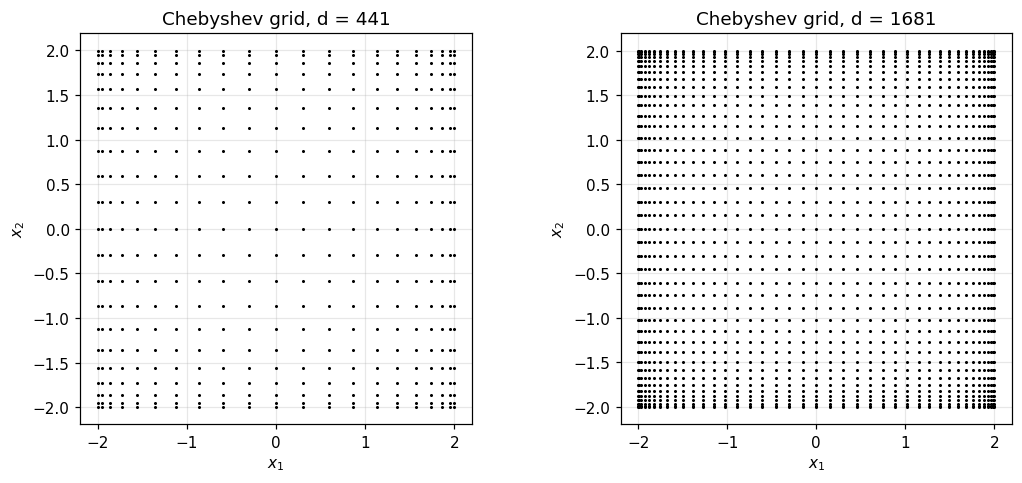

In [3]:
dt_v, nu_v = 0.05, 0.1
def F_vdp(x, u):
    return x + dt_v * np.array([x[1], nu_v * (1 - x[0] ** 2) * x[1] - x[0] + u[0]])

kern = wendland_kernel(2, 1, 1.0)
grids = {d_sqrt ** 2: chebyshev_grid(d_sqrt, 2.0, 2) for d_sqrt in (21, 41)}
surr = {}
for d, Xc in grids.items():
    for eps_name, eps_c in (("sqrt2/d", np.sqrt(2) / d), ("0", 0.0)):
        data = sample_transitions_clusters(F_vdp, Xc, 25, eps_c, -2, 2, 1, rng=0)
        surr[d, eps_name] = KedmdSurrogate(kern, Xc, 25).fit(data)
        print(f"   data generation: {data.n_samples} one-step samples in {data.wall_time:.3f} s;  "
              f"g_hat_0(0) = {surr[d, eps_name].g0(np.zeros(2))}")

fig, ax = plt.subplots(1, 2, figsize=(10, 4.5))
for a, (d, Xc) in zip(ax, grids.items()):
    a.plot(Xc[0], Xc[1], "k.", ms=2)
    a.set(title=f"Chebyshev grid, d = {d}", xlabel="$x_1$", ylabel="$x_2$", aspect="equal")
plt.tight_layout(); plt.show()

### 2.2 One-step prediction error

This is the counterpart of Fig. 4 of the SICON paper: $\max_j \|F(x,u_j) - \hat F(x,u_j)\|$ over 20 input values $u_j \in [-2, 2]$, on $[-1,1]^2$.

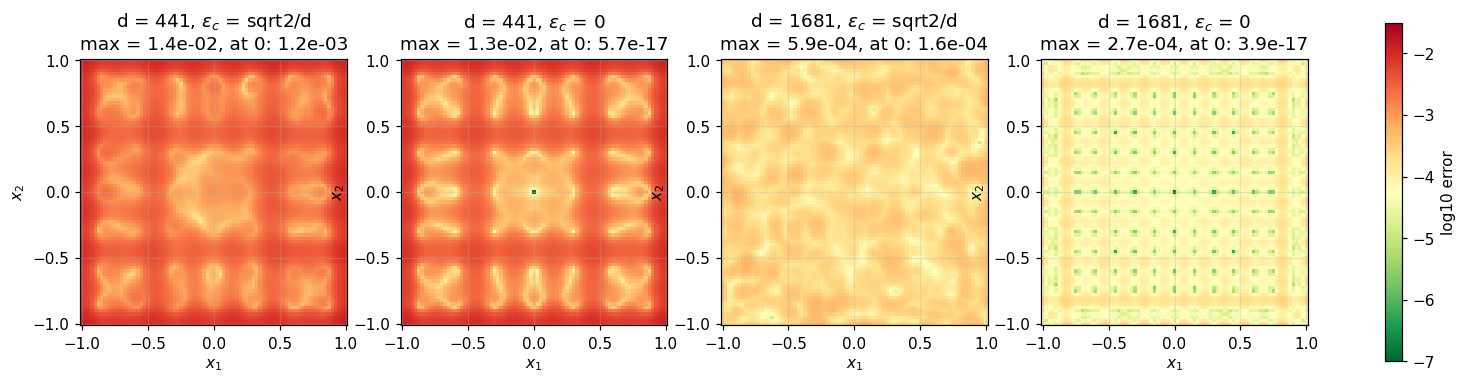

In [4]:
g = np.linspace(-1, 1, 81)
G1, G2 = np.meshgrid(g, g)
Xg = np.vstack([G1.ravel(), G2.ravel()])
u_vals = -2 + 0.2 * np.arange(20)
true_next = {u: np.column_stack([F_vdp(Xg[:, i], [u]) for i in range(Xg.shape[1])]) for u in u_vals}
fig, ax = plt.subplots(1, 4, figsize=(18, 4))
for a, key in zip(ax, [(441, "sqrt2/d"), (441, "0"), (1681, "sqrt2/d"), (1681, "0")]):
    s_ = surr[key]
    err = np.max([np.linalg.norm(s_.step_batch(Xg, np.full((1, Xg.shape[1]), u)) - true_next[u], axis=0)
                  for u in u_vals], axis=0).reshape(G1.shape)
    im = a.pcolormesh(G1, G2, np.log10(err), cmap="RdYlGn_r", vmin=-7, vmax=-1.5, shading="auto")
    a.set(title=f"d = {key[0]}, $\\varepsilon_c$ = {key[1]}\nmax = {err.max():.1e}, at 0: {err[40, 40]:.1e}",
          xlabel="$x_1$", ylabel="$x_2$", aspect="equal")
fig.colorbar(im, ax=ax, label="log10 error"); plt.show()

### 2.3 Is cluster sampling well motivated? A comparison of sampling designs

Step 1 regresses $x^+$ on $[1;\,u]$ inside each cluster, treating all neighbors as if they were located at the center. Its error therefore grows with the cluster radius. We compare four designs for $d = 441$ centers, keeping the total number of samples equal where possible:

| design | samples | cluster radius |
|---|---|---|
| (a) paper: $N_c = 25$ random points per center in a ball of radius $\varepsilon_c = \sqrt2/d$ | $25d$ | $\varepsilon_c$ |
| (b) $N_c = 25$ random inputs exactly at each center, $\varepsilon_c = 0$ | $25d$ | 0 |
| (c) minimal: $N_c = m+1 = 2$ random inputs at each center | $2d$ | 0 |
| (d) "flexible sampling": $25d$ i.i.d. uniform $(x,u)$, with clusters = the 25 nearest neighbors of each center | $25d$ | data-dependent |

In [5]:
Xc = grids[441]
designs = {
    "(a) paper, eps_c = sqrt2/d, N_c = 25": (sample_transitions_clusters(F_vdp, Xc, 25, np.sqrt(2) / 441, -2, 2, 1, rng=0), 25),
    "(b) at centers, N_c = 25":             (sample_transitions_clusters(F_vdp, Xc, 25, 0.0, -2, 2, 1, rng=0), 25),
    "(c) at centers, N_c = m+1 = 2":        (sample_transitions_clusters(F_vdp, Xc, 2, 0.0, -2, 2, 1, rng=0), 2),
    "(d) i.i.d., 25 nearest neighbors":     (sample_transitions_iid(F_vdp, 25 * 441, 2.0, -2, 2, 2, 1, rng=0), 25),
}
Xt = np.random.default_rng(1).uniform(-2, 2, (2, 3000)); Ut = np.random.default_rng(2).uniform(-2, 2, (1, 3000))
Ft = np.column_stack([F_vdp(Xt[:, i], Ut[:, i]) for i in range(3000)])
inner = np.all(np.abs(Xt) <= 1, axis=0)
print(f"\n{'design':40s} {'#data':>6s} {'max radius':>11s} {'err [-2,2]^2':>13s} {'err [-1,1]^2':>13s} {'|g0_hat(0)|':>12s}")
for name, (dat, Nc) in designs.items():
    s_ = KedmdSurrogate(kern, Xc, Nc).fit(dat, report=False)
    e = np.linalg.norm(s_.step_batch(Xt, Ut) - Ft, axis=0)
    print(f"{name:40s} {dat.n_samples:6d} {s_.info['cluster_radius_max']:11.2e} {e.max():13.2e} "
          f"{e[inner].max():13.2e} {np.linalg.norm(s_.g0(np.zeros(2))):12.1e}")


design                                    #data  max radius  err [-2,2]^2  err [-1,1]^2  |g0_hat(0)|
(a) paper, eps_c = sqrt2/d, N_c = 25      11025    3.21e-03      1.88e-02      1.21e-02      3.2e-04


(b) at centers, N_c = 25                  11025    0.00e+00      1.82e-02      1.23e-02      1.5e-17
(c) at centers, N_c = m+1 = 2               882    0.00e+00      1.82e-02      1.23e-02      4.5e-17


(d) i.i.d., 25 nearest neighbors          11025    2.40e-01      1.06e-01      4.57e-02      1.8e-03


- **(b) vs (c):** the Euler-discretized van der Pol map is *exactly* affine in $u$, so $m+1 = 2$ samples per center determine $[g_0(x_\ell)\,|\,G(x_\ell)]$ exactly. The additional 23 random inputs per center add nothing.
- **(a):** with $\varepsilon_c > 0$, the local regression ignores the variation of $g_0$ and $G$ within the ball. The estimate at the origin is then no longer exactly $0$, so the surrogate loses the equilibrium. This causes the offset seen in Part 3.
- **(d):** truly flexible sampling, i.i.d. data with nearest-neighbor clusters, gives cluster radii of order $0.1$–$0.2$. Its errors are 5–10 times larger and the equilibrium is lost.

So the two-level clustering is mainly a device for the *error analysis*, which reduces the problem to pointwise estimates of $g_0$ and $G$ followed by interpolation. When the system can be simulated, the natural design is (c): $m+1$ one-step simulations at each center. Its cost is $d(m+1)$ one-step simulations.

### 2.4 Regularization

$\lambda > 0$ replaces interpolation by kernel ridge regression. This helps when $\mathbf K_{\mathcal X}$ is ill-conditioned or the data are noisy, but generally destroys $\hat g_0(0) = 0$. In this example it survives only because the van der Pol map is odd and the grid is symmetric.

In [6]:
for d, Xc in grids.items():
    dat = sample_transitions_clusters(F_vdp, Xc, 2, 0.0, -2, 2, 1, rng=0)
    for lam in (0.0, 1e-8, 1e-6, 1e-4, 1e-2):
        s_ = KedmdSurrogate(kern, Xc, 2, regularization=lam).fit(dat, report=False)
        e = np.linalg.norm(s_.step_batch(Xt, Ut) - Ft, axis=0)
        print(f"d = {d:4d}, cond(K_X) = {s_.info['cond_K']:.1e}, lambda = {lam:.0e}: "
              f"max error [-2,2]^2 = {e.max():.2e}, [-1,1]^2 = {e[inner].max():.2e}")

d =  441, cond(K_X) = 1.8e+04, lambda = 0e+00: max error [-2,2]^2 = 1.82e-02, [-1,1]^2 = 1.23e-02
d =  441, cond(K_X) = 1.8e+04, lambda = 1e-08: max error [-2,2]^2 = 1.82e-02, [-1,1]^2 = 1.23e-02


d =  441, cond(K_X) = 1.8e+04, lambda = 1e-06: max error [-2,2]^2 = 1.82e-02, [-1,1]^2 = 1.23e-02
d =  441, cond(K_X) = 1.8e+04, lambda = 1e-04: max error [-2,2]^2 = 1.87e-02, [-1,1]^2 = 1.23e-02


d =  441, cond(K_X) = 1.8e+04, lambda = 1e-02: max error [-2,2]^2 = 4.00e-02, [-1,1]^2 = 1.28e-02


d = 1681, cond(K_X) = 3.8e+06, lambda = 0e+00: max error [-2,2]^2 = 2.27e-03, [-1,1]^2 = 2.23e-04


d = 1681, cond(K_X) = 3.8e+06, lambda = 1e-08: max error [-2,2]^2 = 2.27e-03, [-1,1]^2 = 2.23e-04


d = 1681, cond(K_X) = 3.8e+06, lambda = 1e-06: max error [-2,2]^2 = 2.27e-03, [-1,1]^2 = 2.24e-04


d = 1681, cond(K_X) = 3.8e+06, lambda = 1e-04: max error [-2,2]^2 = 2.43e-03, [-1,1]^2 = 2.75e-04


d = 1681, cond(K_X) = 3.8e+06, lambda = 1e-02: max error [-2,2]^2 = 1.28e-02, [-1,1]^2 = 1.94e-03


---
## Part 3. KedmdMPC: reproduction of the IFAC paper's Figs. 1 and 2

- **Settings:** $Q = I_2$, $R = 10^{-4}$, $\mathbb U = [-2, 2]$, $x_0 = (0.5, 0.5)$, with no terminal ingredients. The prediction model is $\hat F$; the plant is the true map $F$.
- **Solver:** IPOPT with multiple shooting. The objective is scaled by $1/(\hat x^\top Q\hat x)$ at each solve, so that the solver's tolerance is relative to the current state; the closed loop reaches states of order $10^{-8}$.

### 3.1 Fig. 1: $N = 10$, $d \in \{441, 1681\}$, $\varepsilon_c \in \{\sqrt2/d,\ 0\}$, 1000 steps

[kEDMD-MPC (Bold et al.), d=441, eps_c=sqrt2/d] closed loop, 1000 steps: total computational time = 22.458 s (OCP solves 21.513 s, mean 21.5 ms)


[kEDMD-MPC (Bold et al.), d=441, eps_c=0] closed loop, 1000 steps: total computational time = 22.198 s (OCP solves 21.255 s, mean 21.3 ms)


[kEDMD-MPC (Bold et al.), d=1681, eps_c=sqrt2/d] closed loop, 1000 steps: total computational time = 78.530 s (OCP solves 77.036 s, mean 77.0 ms)


[kEDMD-MPC (Bold et al.), d=1681, eps_c=0] closed loop, 1000 steps: total computational time = 78.843 s (OCP solves 77.375 s, mean 77.4 ms)


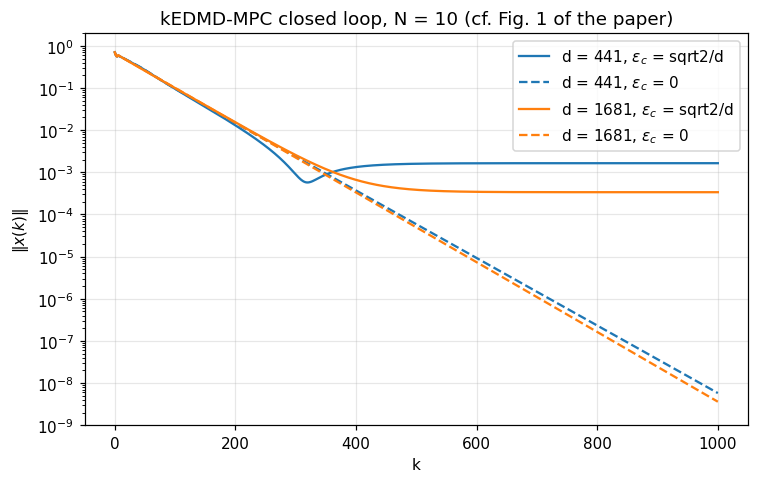

d=441, eps_c=sqrt2/d : |x(500)| = 1.60e-03, |x(1000)| = 1.64e-03, all solves successful: True, max |u| = 2.00
d=441, eps_c=0       : |x(500)| = 5.86e-05, |x(1000)| = 5.79e-09, all solves successful: True, max |u| = 2.00
d=1681, eps_c=sqrt2/d : |x(500)| = 3.84e-04, |x(1000)| = 3.37e-04, all solves successful: True, max |u| = 2.00
d=1681, eps_c=0       : |x(500)| = 4.95e-05, |x(1000)| = 3.61e-09, all solves successful: True, max |u| = 2.00


In [7]:
x0 = np.array([0.5, 0.5])
runs_N10 = {}
for key in [(441, "sqrt2/d"), (441, "0"), (1681, "sqrt2/d"), (1681, "0")]:
    mpc = KedmdMPC(surr[key], horizon=10, Q=np.eye(2), R=1e-4 * np.eye(1), u_min=-2, u_max=2)
    runs_N10[key] = mpc.simulate_closed_loop(F_vdp, x0, 1000, label=f"d={key[0]}, eps_c={key[1]}")

fig, ax = plt.subplots(figsize=(7, 4.5))
for (d, eps), r in runs_N10.items():
    ax.semilogy(r.k, np.linalg.norm(r.x, axis=0), "-" if eps != "0" else "--",
                color="C0" if d == 441 else "C1", label=f"d = {d}, $\\varepsilon_c$ = {eps}")
ax.set(xlabel="k", ylabel="$\\|x(k)\\|$", title="kEDMD-MPC closed loop, N = 10 (cf. Fig. 1 of the paper)",
       ylim=(1e-9, 2)); ax.legend(); plt.tight_layout(); plt.show()
for key, r in runs_N10.items():
    print(f"d={key[0]}, eps_c={key[1]:8s}: |x(500)| = {np.linalg.norm(r.x[:, 500]):.2e}, "
          f"|x(1000)| = {np.linalg.norm(r.x[:, 1000]):.2e}, all solves successful: {r.success.all()}, "
          f"max |u| = {np.abs(r.u).max():.2f}")

### 3.2 Fig. 2: $N = 20$, $d = 441$, 500 steps

[kEDMD-MPC (Bold et al.), N=20, d=441, eps_c=sqrt2/d] closed loop, 500 steps: total computational time = 24.201 s (OCP solves 23.328 s, mean 46.7 ms)


[kEDMD-MPC (Bold et al.), N=20, d=441, eps_c=0] closed loop, 500 steps: total computational time = 25.992 s (OCP solves 25.074 s, mean 50.1 ms)


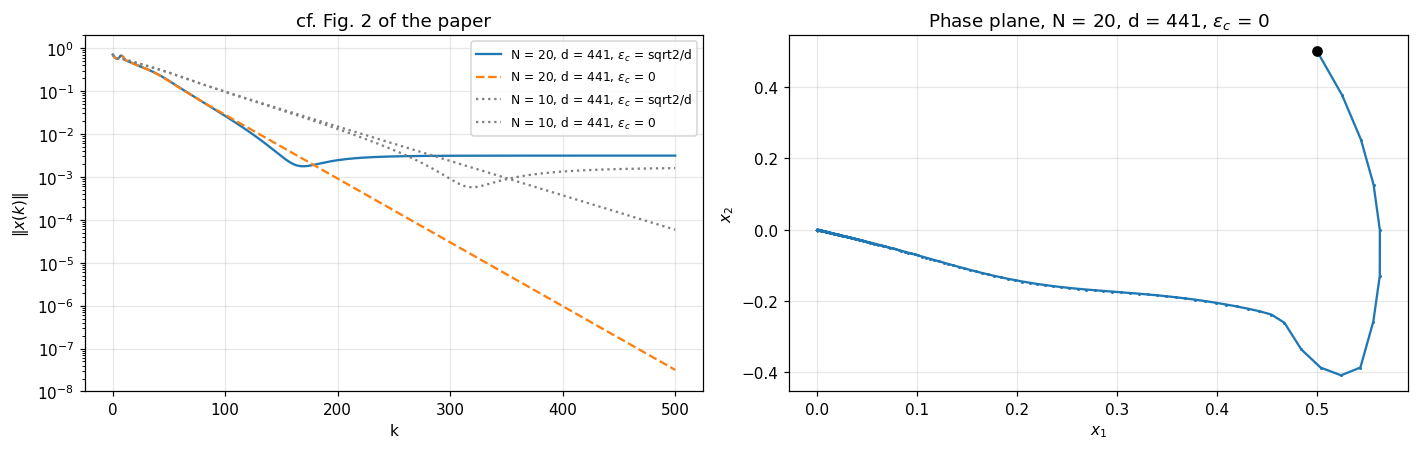

In [8]:
runs_N20 = {}
for key in [(441, "sqrt2/d"), (441, "0")]:
    mpc = KedmdMPC(surr[key], horizon=20, Q=np.eye(2), R=1e-4 * np.eye(1), u_min=-2, u_max=2)
    runs_N20[key] = mpc.simulate_closed_loop(F_vdp, x0, 500, label=f"N=20, d={key[0]}, eps_c={key[1]}")
fig, ax = plt.subplots(1, 2, figsize=(13, 4.2))
for (d, eps), r in runs_N20.items():
    ax[0].semilogy(r.k, np.linalg.norm(r.x, axis=0), "-" if eps != "0" else "--",
                   label=f"N = 20, d = {d}, $\\varepsilon_c$ = {eps}")
for (d, eps), r in runs_N10.items():
    if d == 441:
        ax[0].semilogy(r.k[:501], np.linalg.norm(r.x[:, :501], axis=0), ":", color="gray",
                       label=f"N = 10, d = {d}, $\\varepsilon_c$ = {eps}")
ax[0].set(xlabel="k", ylabel="$\\|x(k)\\|$", ylim=(1e-8, 2), title="cf. Fig. 2 of the paper"); ax[0].legend(fontsize=8)
r = runs_N20[441, "0"]
ax[1].plot(r.x[0], r.x[1], ".-", ms=2); ax[1].plot(*x0, "ko")
ax[1].set(xlabel="$x_1$", ylabel="$x_2$", title="Phase plane, N = 20, d = 441, $\\varepsilon_c$ = 0")
plt.tight_layout(); plt.show()

**Comparison with the paper.** The values read from the paper's figures are approximate.

| | paper | here |
|---|---|---|
| Fig. 1, $N=10$, $\varepsilon_c=\sqrt2/d$: offset | ≈ $3\cdot10^{-3}$ ($d=441$), ≈ $3\cdot10^{-4}$ ($d=1681$), reached after ≈ 400–500 steps | $1.6\cdot10^{-3}$ ($d=441$), $3.4\cdot10^{-4}$ ($d=1681$), reached after ≈ 400–500 steps |
| Fig. 1, $N=10$, $\varepsilon_c=0$: $\|x(1000)\|$ | ≈ $10^{-8}$, exponential decay | $5.8\cdot10^{-9}$ ($d=441$), $3.6\cdot10^{-9}$ ($d=1681$) |
| Fig. 2, $N=20$, $d=441$: offset ($\varepsilon_c=\sqrt2/d$) | ≈ $5\cdot10^{-3}$ | ≈ $3\cdot10^{-3}$ |
| Fig. 2, $N=20$, $d=441$: $\|x(500)\|$ ($\varepsilon_c=0$) | ≈ $5\cdot10^{-8}$ | $3\cdot10^{-8}$ |

The qualitative behavior is reproduced:

- With $\varepsilon_c > 0$, the closed loop is only *practically* stable. The offset shrinks with $d$ and comes from $\hat g_0(0) \neq 0$ (Part 2).
- With $\varepsilon_c = 0$, the origin is an exact equilibrium of the surrogate and the convergence is exponential.
- $N = 20$ converges faster than $N = 10$.

The remaining quantitative differences are plausibly due to the random cluster data (different seeds), the normalization of the Wendland kernel ($\phi(0) = 1$ here, $1/20$ in the paper, which does not affect the interpolant), and IPOPT tolerances.